# SIGK Projekt 1 - Denoising, Inpainting
### Grzegorz Siudak, Rafał Wyszyński

In [7]:
%pip install -q lpips gdown

In [47]:
import copy, math, random, shutil, subprocess, sys, zlib
from pathlib import Path
from zipfile import ZipFile

import cv2
import lpips
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import denoise_bilateral
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
IMAGE_SIZE = 256
NUM_WORKERS = 0
VAL_COUNT = 80
SIGMAS = (0.01, 0.03)
HOLE_SIZES = (3, 32)

BATCH_SIZE_DENOISE = 16
EPOCHS_DENOISE = 40
LR_DENOISE = 1e-4
DENOISE_CONFIGS = {"CNN 32x6": (32, 6), "CNN 64x8": (64, 8)}

CROP = 128
REPEAT = 8
BATCH_SIZE_INPAINT = 64
UNET_BASE = 48
EPOCHS_UNET = 60
LR_UNET = 3e-4
EMA_UNET = 0.999

EPOCHS_GAN = 40
LR_GAN_G = 1.4e-4
LR_GAN_D = 2e-4
ADV_W = 0.01
FM_W = 0.5
TV_W = 0.1
GAN_RAMP = 3
EMA_GAN = 0.998
D_WINDOW = 80
D_BASE = 64

VAL_EVERY = 5
GAN_SELECT = "last"
TTA_FINAL = True
LOAD_IF_EXISTS = True

OUTPUT_DIR = Path("results_div2k")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "val_samples").mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Dataset

In [42]:
DATA_DIR = Path(".")
def find_dir(name):
    found = list(DATA_DIR.rglob(name))
    return found[0] if found else None

DIV2K_TRAIN_DIR = find_dir("DIV2K_train_HR_256")
DIV2K_VALID_DIR = find_dir("DIV2K_valid_HR_256")

if DIV2K_TRAIN_DIR is None or DIV2K_VALID_DIR is None:
    archive = Path("DIV2K_256x256.zip")
    if not archive.exists():
        import gdown
        gdown.download(id="1uOhZ6y6ShyWDH0NBaKEMOFiKtDQuceOK", output=str(archive), quiet=False)
    with ZipFile(archive) as z:
        z.extractall(".")
    DIV2K_TRAIN_DIR = find_dir("DIV2K_train_HR_256")
    DIV2K_VALID_DIR = find_dir("DIV2K_valid_HR_256")

assert DIV2K_TRAIN_DIR and DIV2K_VALID_DIR, "DIV2K folders not found"
print(DIV2K_TRAIN_DIR, DIV2K_VALID_DIR)

DIV2K_train_HR_256 DIV2K_valid_HR_256


Train: 720 | Validation: 80 | Test: 100


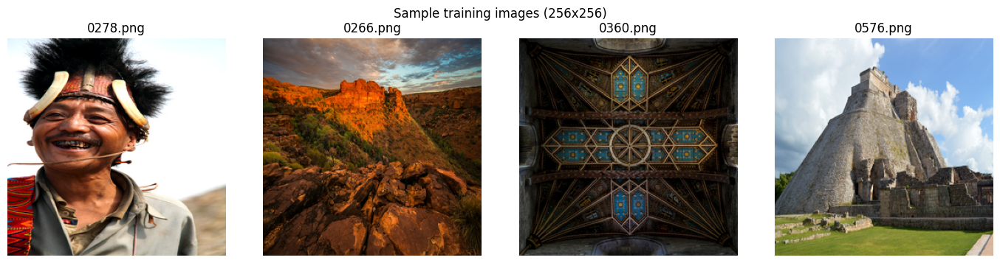

In [43]:
def list_images(folder):
    exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in exts)

def load_rgb(path, size=IMAGE_SIZE):
    im = Image.open(path).convert("RGB")
    if im.size != (size, size):
        im = im.resize((size, size), Image.Resampling.LANCZOS)
    return np.asarray(im).astype(np.float32) / 255.0

class DIV2KDataset(Dataset):
    def __init__(self, paths, size=IMAGE_SIZE, augment=False):
        self.paths, self.size, self.augment = list(paths), size, augment
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = torch.from_numpy(load_rgb(self.paths[idx], self.size)).permute(2, 0, 1).contiguous()
        if self.augment:
            if random.random() < 0.5: img = torch.flip(img, dims=[2])
            if random.random() < 0.5: img = torch.flip(img, dims=[1])
        return img

all_train_paths = list_images(DIV2K_TRAIN_DIR)
test_paths = list_images(DIV2K_VALID_DIR)
random.Random(SEED).shuffle(all_train_paths)
val_paths = all_train_paths[:VAL_COUNT]
train_paths = all_train_paths[VAL_COUNT:]

train_loader = DataLoader(DIV2KDataset(train_paths, augment=True), batch_size=BATCH_SIZE_DENOISE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
print(f"Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, p in zip(axes, train_paths[:4]):
    ax.imshow(load_rgb(p)); ax.set_title(p.name); ax.axis("off")
plt.suptitle("Sample training images (256x256)"); plt.tight_layout(); plt.show()

## Metrics

In [44]:
lpips_alex = lpips.LPIPS(net="alex").to(DEVICE).eval()
lpips_vgg = lpips.LPIPS(net="vgg").to(DEVICE).eval()

def to_tensor(img_hwc):
    return torch.from_numpy(img_hwc).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

@torch.no_grad()
def compute_metrics(pred, target):
    pred, target = pred.detach().clamp(0, 1), target.detach().clamp(0, 1)
    sne = torch.sum((pred - target) ** 2).item()
    p = pred[0].permute(1, 2, 0).cpu().numpy()
    t = target[0].permute(1, 2, 0).cpu().numpy()
    psnr = peak_signal_noise_ratio(t, p, data_range=1.0)
    psnr = 100.0 if np.isinf(psnr) else float(psnr)
    ssim = structural_similarity(t, p, data_range=1.0, channel_axis=2)
    return {
        "PSNR": psnr, "SSIM": float(ssim), "SNE": float(sne),
        "LPIPS_Alex": float(lpips_alex(pred * 2 - 1, target * 2 - 1).mean().item()),
        "LPIPS_VGG": float(lpips_vgg(pred * 2 - 1, target * 2 - 1).mean().item()),
    }

@torch.no_grad()
def hole_psnr(pred, clean, mask):
    mse = (((pred - clean) ** 2) * mask).sum() / (mask.sum() * 3)
    return float((10 * torch.log10(1 / mse.clamp_min(1e-10))).item())

METRIC_COLS = ["PSNR", "SSIM", "SNE", "LPIPS_Alex", "LPIPS_VGG"]
METRIC_ARROWS = {"PSNR_hole": "PSNR hole ↑", "PSNR": "PSNR ↑", "SSIM": "SSIM ↑", "SNE": "SNE ↓",
                 "LPIPS_Alex": "LPIPS (Alex) ↓", "LPIPS_VGG": "LPIPS (VGG) ↓"}

def save_history(df, path):
    df.to_csv(path, index=False)

def load_history(path):
    return pd.read_csv(path) if path.exists() else None

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth


## Denoising

In [48]:
def fixed_noisy_image(path, sigma):
    clean = load_rgb(path)
    rng = np.random.default_rng(zlib.crc32(f"{path.name}-{sigma}-{SEED}".encode()))
    noisy = np.clip(clean + rng.normal(0, sigma, clean.shape), 0, 1).astype(np.float32)
    return clean, noisy

class DenoiseCNN(nn.Module):
    def __init__(self, channels=32, depth=6):
        super().__init__()
        layers = [nn.Conv2d(4, channels, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(inplace=True)]
        layers.append(nn.Conv2d(channels, 3, 3, padding=1))
        self.net = nn.Sequential(*layers)
    def forward(self, noisy, sigma):
        sigma_map = torch.full_like(noisy[:, :1], sigma)
        predicted_noise = self.net(torch.cat([noisy, sigma_map], dim=1))
        return (noisy - predicted_noise).clamp(0, 1)

val_denoise = {s: [fixed_noisy_image(p, s) for p in val_paths] for s in SIGMAS}

@torch.no_grad()
def denoise_val_loss(model):
    model.eval()
    losses = []
    for sigma in SIGMAS:
        for clean_np, noisy_np in val_denoise[sigma]:
            losses.append(F.mse_loss(model(to_tensor(noisy_np), sigma), to_tensor(clean_np)).item())
    return float(np.mean(losses))

def train_denoiser(model, name):
    opt = torch.optim.Adam(model.parameters(), lr=LR_DENOISE)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_DENOISE)
    best, best_state, rows = float("inf"), copy.deepcopy(model.state_dict()), []
    for epoch in range(EPOCHS_DENOISE):
        model.train()
        total, count = 0.0, 0
        for clean in tqdm(train_loader, desc=f"{name} {epoch+1}/{EPOCHS_DENOISE}"):
            clean = clean.to(DEVICE, non_blocking=True)
            sigma = random.choice(SIGMAS)
            noisy = (clean + torch.randn_like(clean) * sigma).clamp(0, 1)
            loss = F.mse_loss(model(noisy, sigma), clean)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            total += loss.item() * clean.size(0); count += clean.size(0)
        sched.step()
        val = denoise_val_loss(model)
        rows.append({"epoch": epoch + 1, "train_mse": total / count, "val_mse": val})
        print(f"{name}, epoch {epoch+1}: train={total/count:.5f}  val={val:.5f}")
        if val < best:
            best, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return pd.DataFrame(rows)

denoisers, denoise_histories = {}, {}

for name, (ch, depth) in DENOISE_CONFIGS.items():
    model = DenoiseCNN(ch, depth).to(DEVICE)

    ckpt = OUTPUT_DIR / f"{name.replace(' ', '_')}_ep{EPOCHS_DENOISE}.pth"
    hist_path = OUTPUT_DIR / f"{name.replace(' ', '_')}_history.csv"

    denoise_histories[name] = train_denoiser(model, name)

    torch.save(model.state_dict(), ckpt)
    save_history(denoise_histories[name], hist_path)

    denoisers[name] = model.eval()

    print(f"{name}: {sum(p.numel() for p in model.parameters())/1e3:.0f}k parameters")

CNN 32x6 1/40:   0%|          | 0/45 [00:00<?, ?it/s]

CNN 32x6, epoch 1: train=0.00056  val=0.00049


CNN 32x6 2/40:   0%|          | 0/45 [00:00<?, ?it/s]

CNN 32x6, epoch 2: train=0.00051  val=0.00049


CNN 32x6 3/40:   0%|          | 0/45 [00:00<?, ?it/s]

CNN 32x6, epoch 3: train=0.00036  val=0.00049


... (150 outputs left out)

CNN 64x8 39/40:   0%|          | 0/45 [00:00<?, ?it/s]

CNN 64x8, epoch 39: train=0.00027  val=0.00026


CNN 64x8 40/40:   0%|          | 0/45 [00:00<?, ?it/s]

CNN 64x8, epoch 40: train=0.00026  val=0.00026
CNN 64x8: 226k parameters


In [49]:
BILATERAL_CANDIDATES = [(0.75, 1.0), (1.0, 1.5), (1.5, 2.0)]

def bilateral_filter(image, sigma, params):
    color_scale, spatial = params
    return denoise_bilateral(image, sigma_color=color_scale * sigma, sigma_spatial=spatial,
                             channel_axis=-1).astype(np.float32)

bilateral_params = {}
for sigma in SIGMAS:
    scores = []
    for params in BILATERAL_CANDIDATES:
        vals = [peak_signal_noise_ratio(c, bilateral_filter(n, sigma, params), data_range=1.0)
                for c, n in val_denoise[sigma][:20]]
        scores.append((float(np.mean(vals)), params))
    bilateral_params[sigma] = max(scores)[1]
    print(f"sigma={sigma}: bilateral params = {bilateral_params[sigma]}")

@torch.no_grad()
def evaluate_denoising(models, paths):
    rows = []
    for sigma in SIGMAS:
        for path in tqdm(paths, desc=f"Denoising eval sigma={sigma}"):
            clean_np, noisy_np = fixed_noisy_image(path, sigma)
            clean, noisy = to_tensor(clean_np), to_tensor(noisy_np)
            bil = to_tensor(bilateral_filter(noisy_np, sigma, bilateral_params[sigma]))
            cands = [("Noisy input", noisy), ("Bilateral", bil)]
            cands += [(n, m(noisy, sigma)) for n, m in models.items()]
            for method, result in cands:
                rows.append({"task": "denoising", "setting": f"sigma={sigma}", "image": path.name,
                             "method": method, **compute_metrics(result, clean)})
    return pd.DataFrame(rows)

denoise_results = evaluate_denoising(denoisers, test_paths)
denoise_summary = denoise_results.groupby(["setting", "method"], sort=False)[METRIC_COLS].mean().reset_index()
display(denoise_summary.rename(columns=METRIC_ARROWS))
denoise_results.to_csv(OUTPUT_DIR / "denoising_per_image.csv", index=False)
denoise_summary.rename(columns=METRIC_ARROWS).to_csv(OUTPUT_DIR / "denoising_summary.csv", index=False)

sigma=0.01: bilateral params = (0.75, 1.0)
sigma=0.03: bilateral params = (0.75, 1.0)


Denoising eval sigma=0.01:   0%|          | 0/100 [00:00<?, ?it/s]

Denoising eval sigma=0.03:   0%|          | 0/100 [00:00<?, ?it/s]

,setting,method,PSNR ↑,SSIM ↑,SNE ↓,LPIPS (Alex) ↓,LPIPS (VGG) ↓
0,sigma=0.01,Noisy input,40.076378,0.972854,19.331253,0.008314,0.050127
1,sigma=0.01,Bilateral,37.307911,0.977970,38.909135,0.007530,0.042922
2,sigma=0.01,CNN 32x6,40.370813,0.983790,19.071969,0.007835,0.044685
3,sigma=0.01,CNN 64x8,40.611053,0.986195,18.150780,0.007543,0.042502
4,sigma=0.03,Noisy input,30.609065,0.841264,171.097100,0.065428,0.149589
5,sigma=0.03,Bilateral,30.843195,0.908679,171.217742,0.044380,0.145968
6,sigma=0.03,CNN 32x6,33.167407,0.905607,95.376526,0.059581,0.135760
7,sigma=0.03,CNN 64x8,33.910188,0.924516,81.037840,0.056762,0.130066


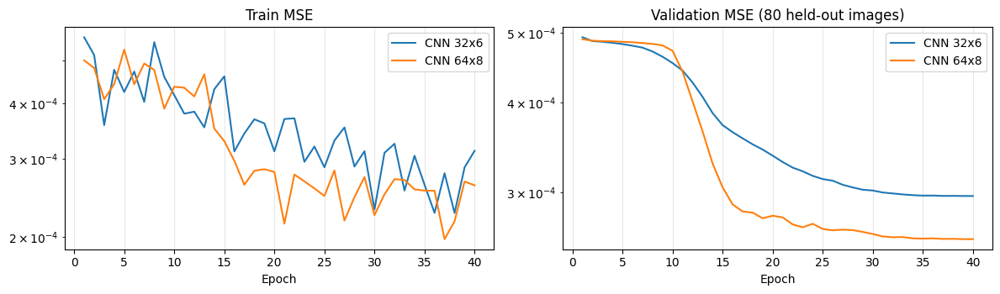

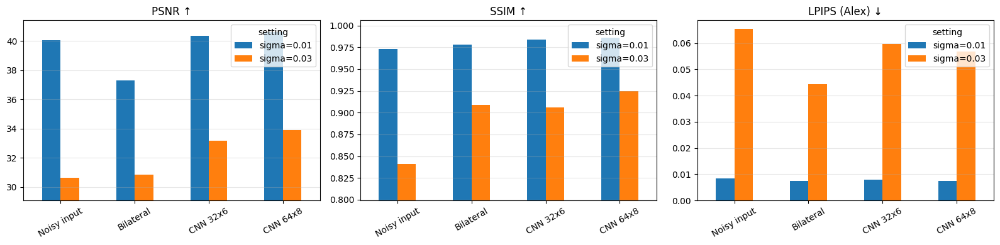

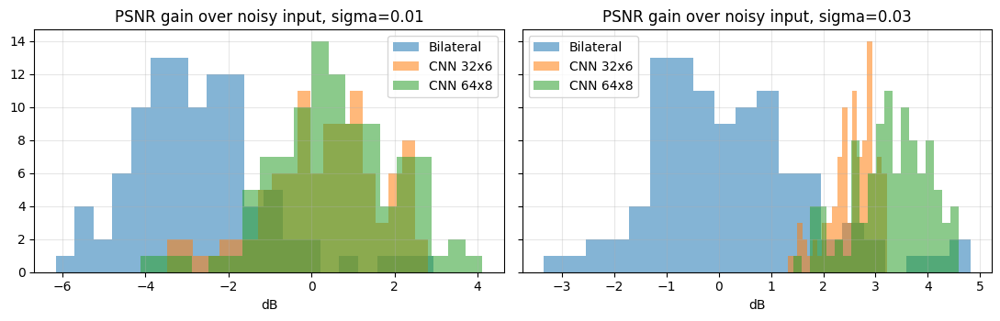

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


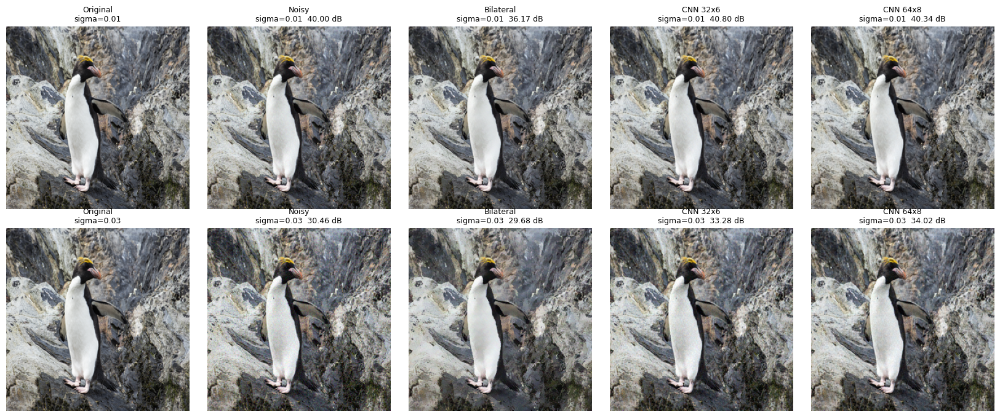

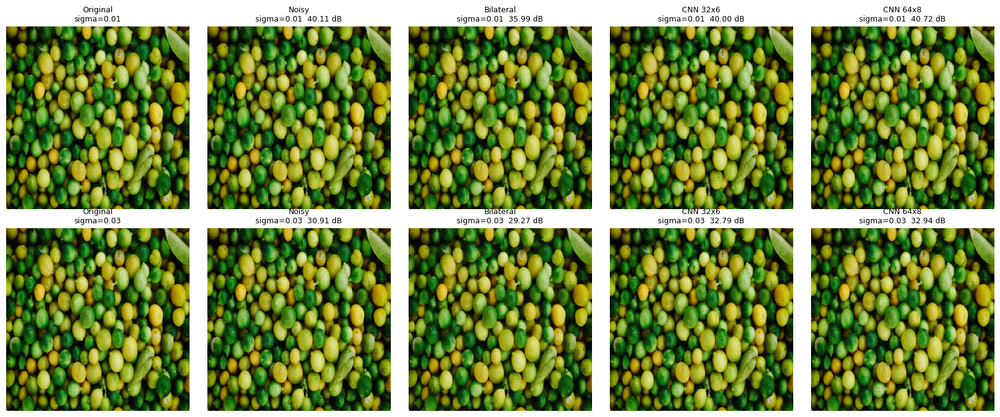

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for name, h in denoise_histories.items():
    if h is None: continue
    axes[0].plot(h["epoch"], h["train_mse"], label=name)
    axes[1].plot(h["epoch"], h["val_mse"], label=name)
for ax, t in zip(axes, ["Train MSE", "Validation MSE (80 held-out images)"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.set_yscale("log"); ax.grid(True, alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

order = list(dict.fromkeys(denoise_summary["method"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["PSNR", "SSIM", "LPIPS_Alex"]):
    piv = denoise_summary.pivot(index="method", columns="setting", values=metric).reindex(order)
    piv.plot.bar(ax=ax, rot=30)
    ax.set_title(METRIC_ARROWS[metric]); ax.set_xlabel(""); ax.grid(axis="y", alpha=.3)
    if metric in ("PSNR", "SSIM"):
        ax.set_ylim(piv.min().min() * 0.95, piv.max().max() * 1.02)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(SIGMAS), figsize=(11, 3.6), sharey=True)
for ax, sigma in zip(axes, SIGMAS):
    d = denoise_results[denoise_results["setting"] == f"sigma={sigma}"].pivot(index="image", columns="method", values="PSNR")
    for m in [c for c in d.columns if c != "Noisy input"]:
        ax.hist(d[m] - d["Noisy input"], bins=20, alpha=.55, label=m)
    ax.set_title(f"PSNR gain over noisy input, sigma={sigma}"); ax.set_xlabel("dB"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

@torch.no_grad()
def show_denoising_example(path):
    names = ["Original", "Noisy", "Bilateral", *denoisers.keys()]
    fig, axes = plt.subplots(len(SIGMAS), len(names), figsize=(3.3 * len(names), 3.4 * len(SIGMAS)))
    for r, sigma in enumerate(SIGMAS):
        clean, noisy = fixed_noisy_image(path, sigma)
        imgs = [clean, noisy, bilateral_filter(noisy, sigma, bilateral_params[sigma])]
        imgs += [m(to_tensor(noisy), sigma)[0].permute(1, 2, 0).cpu().numpy() for m in denoisers.values()]
        for ax, im, n in zip(axes[r], imgs, names):
            psnr = peak_signal_noise_ratio(clean, im.clip(0, 1), data_range=1.0)
            ax.imshow(im.clip(0, 1)); ax.axis("off")
            ax.set_title(f"{n}\nsigma={sigma}" + ("" if n == "Original" else f"  {psnr:.2f} dB"), fontsize=9)
    plt.tight_layout(); plt.show()

for p in test_paths[:2]:
    show_denoising_example(p)

In [51]:
from pathlib import Path
import shutil

SAVE_DIR = OUTPUT_DIR / "test_comparisons_denoising"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

@torch.no_grad()
def save_denoising_example(path):
    names = ["Original", "Noisy", "Bilateral", *denoisers.keys()]
    fig, axes = plt.subplots(len(SIGMAS), len(names), figsize=(3.3 * len(names), 3.4 * len(SIGMAS)))
    for r, sigma in enumerate(SIGMAS):
        clean, noisy = fixed_noisy_image(path, sigma)
        imgs = [clean, noisy, bilateral_filter(noisy, sigma, bilateral_params[sigma])]
        imgs += [m(to_tensor(noisy), sigma)[0].permute(1, 2, 0).cpu().numpy() for m in denoisers.values()]
        for ax, im, n in zip(axes[r], imgs, names):
            psnr = peak_signal_noise_ratio(clean, im.clip(0, 1), data_range=1.0)
            ax.imshow(im.clip(0, 1)); ax.axis("off")
            ax.set_title(f"{n}\nsigma={sigma}" + ("" if n == "Original" else f"  {psnr:.2f} dB"), fontsize=9)
    fig.suptitle(path.name, fontsize=12)
    plt.tight_layout()
    fig.savefig(SAVE_DIR / f"{path.stem}_denoising.png", dpi=110, bbox_inches="tight")
    plt.close(fig)

for p in tqdm(test_paths, desc="Saving denoising comparisons"):
    save_denoising_example(p)

shutil.make_archive(str(OUTPUT_DIR / "test_comparisons_denoising"), "zip", SAVE_DIR)
print(f"Saved {len(list(SAVE_DIR.glob('*.png')))} images to {SAVE_DIR.resolve()}")

Saving denoising comparisons:   0%|          | 0/100 [00:00<?, ?it/s]

Saved 100 images to /content/results_div2k/test_comparisons_denoising


## Inpainting

In [16]:
class InpaintTrainDS(Dataset):
    def __init__(self, paths, crop=CROP, repeat=REPEAT):
        self.imgs = [torch.from_numpy((load_rgb(p) * 255).astype(np.uint8)).permute(2, 0, 1).contiguous()
                     for p in paths]
        self.crop, self.repeat = crop, repeat
    def __len__(self): return len(self.imgs) * self.repeat
    def __getitem__(self, i):
        img = self.imgs[i % len(self.imgs)].float() / 255
        _, H, W = img.shape
        y, x = random.randint(0, H - self.crop), random.randint(0, W - self.crop)
        img = img[:, y:y+self.crop, x:x+self.crop]
        img = torch.rot90(img, random.randint(0, 3), dims=(1, 2))
        if random.random() < 0.5: img = torch.flip(img, dims=[2])
        b, c = random.uniform(0.9, 1.1), random.uniform(0.9, 1.1)
        m = img.mean()
        img = ((img - m) * c + m) * b
        return img.clamp(0, 1).contiguous()

inpaint_ds = InpaintTrainDS(train_paths)
inpaint_loader = DataLoader(inpaint_ds, batch_size=BATCH_SIZE_INPAINT, shuffle=True, drop_last=True,
                            num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                            persistent_workers=NUM_WORKERS > 0)
print(f"Inpainting: {len(train_paths)} images x {REPEAT} repeats = {len(inpaint_ds)} crops/epoch, "
      f"{len(inpaint_loader)} steps/epoch")

def make_masks(B, H, W, sizes, device, rng=random):
    mask = torch.zeros(B, 1, H, W)
    for i, s in enumerate(sizes):
        s = min(s, H, W)
        y, x = rng.randint(0, H - s), rng.randint(0, W - s)
        mask[i, :, y:y+s, x:x+s] = 1.0
    return mask.to(device)

def apply_inpainting_mask(clean, sizes, rng=random):
    mask = make_masks(clean.shape[0], clean.shape[-2], clean.shape[-1], sizes, clean.device, rng)
    return clean * (1 - mask), mask

def fixed_mask(path, hole_size):
    rng = np.random.default_rng(zlib.crc32(f"{path.name}-{hole_size}-{SEED}".encode()))
    y = int(rng.integers(0, IMAGE_SIZE - hole_size + 1))
    x = int(rng.integers(0, IMAGE_SIZE - hole_size + 1))
    mask = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.float32)
    mask[y:y+hole_size, x:x+hole_size] = 1.0
    return mask, y, x

class GConv(nn.Module):
    def __init__(self, cin, cout, k=3, stride=1, dilation=1):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout * 2, k, stride, dilation * (k - 1) // 2, dilation)
        self.norm = nn.GroupNorm(8, cout)
    def forward(self, x):
        f, g = self.conv(x).chunk(2, dim=1)
        return self.norm(F.silu(f)) * torch.sigmoid(g)

class ResG(nn.Module):
    def __init__(self, ch, dilation=1):
        super().__init__()
        self.c1 = GConv(ch, ch, dilation=dilation)
        self.c2 = GConv(ch, ch)
    def forward(self, x): return x + self.c2(self.c1(x))

class SelfAttn(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first=True)
        self.gamma = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        B, C, H, W = x.shape
        t = self.norm(x).flatten(2).transpose(1, 2)
        o, _ = self.attn(t, t, t, need_weights=False)
        return x + self.gamma * o.transpose(1, 2).reshape(B, C, H, W)

class GatedUNet(nn.Module):
    def __init__(self, base=48):
        super().__init__()
        c = [base, base*2, base*4, base*8]
        self.stem = GConv(4, c[0]);               self.enc1 = ResG(c[0])
        self.down1 = GConv(c[0], c[1], stride=2); self.enc2 = ResG(c[1])
        self.down2 = GConv(c[1], c[2], stride=2); self.enc3 = ResG(c[2])
        self.down3 = GConv(c[2], c[3], stride=2)
        self.mid = nn.Sequential(ResG(c[3], 1), ResG(c[3], 2), SelfAttn(c[3]), ResG(c[3], 4), ResG(c[3], 1))
        self.dec3 = nn.Sequential(GConv(c[3] + c[2], c[2]), ResG(c[2]))
        self.dec2 = nn.Sequential(GConv(c[2] + c[1], c[1]), ResG(c[1]))
        self.dec1 = nn.Sequential(GConv(c[1] + c[0], c[0]), ResG(c[0]))
        self.out = nn.Conv2d(c[0], 3, 1)
    @staticmethod
    def up(x): return F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
    def forward(self, image_with_holes, mask):
        x = torch.cat([image_with_holes, mask], dim=1)
        e1 = self.enc1(self.stem(x))
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        b = self.mid(self.down3(e3))
        d3 = self.dec3(torch.cat([self.up(b), e3], 1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], 1))
        raw = torch.sigmoid(self.out(d1))
        comp = raw * mask + image_with_holes * (1 - mask)
        return raw, comp

class SNPatchD(nn.Module):
    def __init__(self, base=64):
        super().__init__()
        sn = nn.utils.spectral_norm
        def blk(cin, cout, stride):
            return nn.Sequential(sn(nn.Conv2d(cin, cout, 4, stride, 1)), nn.LeakyReLU(0.2, inplace=True))
        self.b1 = blk(4, base, 2)
        self.b2 = blk(base, base * 2, 2)
        self.b3 = blk(base * 2, base * 4, 2)
        self.b4 = blk(base * 4, base * 4, 1)
        self.out = sn(nn.Conv2d(base * 4, 1, 4, 1, 1))
    def forward(self, img, mask):
        x = torch.cat([img, mask], 1)
        f1 = self.b1(x); f2 = self.b2(f1); f3 = self.b3(f2); f4 = self.b4(f3)
        return self.out(f4), [f1, f2, f3, f4]

def diff_aug(imgs, mask):
    k = random.randint(0, 3)
    imgs = [torch.rot90(i, k, (2, 3)) for i in imgs]; mask = torch.rot90(mask, k, (2, 3))
    if random.random() < 0.5:
        imgs = [i.flip(3) for i in imgs]; mask = mask.flip(3)
    B = mask.size(0)
    b = torch.empty(B, 1, 1, 1, device=mask.device).uniform_(0.85, 1.15)
    c = torch.empty(B, 1, 1, 1, device=mask.device).uniform_(0.85, 1.15)
    out = []
    for i in imgs:
        m = i.mean((1, 2, 3), keepdim=True)
        out.append((((i - m) * c + m) * b).clamp(0, 1))
    return out, mask

def crop_around_hole(tensors, mask, win=D_WINDOW, hole=max(HOLE_SIZES)):
    B, _, H, W = mask.shape
    y0 = mask.amax(3)[:, 0].argmax(1); x0 = mask.amax(2)[:, 0].argmax(1)
    ctx = (win - hole) // 2
    ts = (y0 - ctx).clamp(0, H - win).tolist(); ls = (x0 - ctx).clamp(0, W - win).tolist()
    out = [torch.stack([t[i, :, ts[i]:ts[i] + win, ls[i]:ls[i] + win] for i in range(B)])
           for t in list(tensors) + [mask]]
    return out[:-1], out[-1]

def inpaint_loss(raw, clean, mask):
    hole = ((raw - clean).abs() * mask).sum() / (mask.sum() * 3 + 1e-8)
    valid = ((raw - clean).abs() * (1 - mask)).mean()
    return hole + 0.1 * valid

def tv_loss(comp, mask):
    R = F.max_pool2d(mask, 3, 1, 1)
    rx = R[..., :, 1:] * R[..., :, :-1]
    ry = R[..., 1:, :] * R[..., :-1, :]
    dx = (comp[..., :, 1:] - comp[..., :, :-1]).abs()
    dy = (comp[..., 1:, :] - comp[..., :-1, :]).abs()
    return (dx * rx).sum() / (rx.sum() * 3 + 1e-8) + (dy * ry).sum() / (ry.sum() * 3 + 1e-8)

def inpaint_loss_tv(raw, comp, clean, mask, w_hole=1.0, w_valid=0.1, w_tv=TV_W):
    hole = ((raw - clean).abs() * mask).sum() / (mask.sum() * 3 + 1e-8)
    valid = ((raw - clean).abs() * (1 - mask)).mean()
    return w_hole * hole + w_valid * valid + w_tv * tv_loss(comp, mask), hole

print(f"Gated U-Net: {sum(p.numel() for p in GatedUNet(UNET_BASE).parameters())/1e6:.1f} M parameters | "
      f"Discriminator: {sum(p.numel() for p in SNPatchD(D_BASE).parameters())/1e6:.1f} M parameters")


Inpainting: 720 images x 8 repeats = 5760 crops/epoch, 90 steps/epoch
Gated U-Net: 29.7 M parameters | Discriminator: 1.7 M parameters


### 4.2 Validation set, prediction helper, checkpoint selection

The 80 validation images get one **fixed** hole each (per hole size), so every number logged during training is comparable between epochs and models. `validate()` returns the hole-PSNR for 3x3 and 32x32 holes and LPIPS on the 32x32 completions.


In [17]:
def build_fixed_set(paths):
    clean = torch.stack([torch.from_numpy(load_rgb(p)).permute(2, 0, 1).contiguous() for p in paths])
    masks = {s: torch.stack([torch.from_numpy(fixed_mask(p, s)[0])[None] for p in paths]) for s in HOLE_SIZES}
    return clean, masks

VAL_SET = build_fixed_set(val_paths)
BIG = max(HOLE_SIZES)

@torch.no_grad()
def validate(model, fixed=VAL_SET, bs=16):
    model.eval()
    clean_all, masks = fixed
    out = {}
    for s in HOLE_SIZES:
        ps, lp = [], []
        for i in range(0, len(clean_all), bs):
            clean, mask = clean_all[i:i+bs].to(DEVICE), masks[s][i:i+bs].to(DEVICE)
            comp = model(clean * (1 - mask), mask)[1].clamp(0, 1)
            mse = (((comp - clean) ** 2) * mask).sum((1, 2, 3)) / (mask.sum((1, 2, 3)) * 3)
            ps.append(10 * torch.log10(1 / mse.clamp_min(1e-10)))
            if s == BIG:
                lp.append(lpips_alex(comp * 2 - 1, clean * 2 - 1).flatten())
        out[f"val_psnr_hole_{s}"] = torch.cat(ps).mean().item()
    out["val_lpips_big"] = torch.cat(lp).mean().item()
    return out

@torch.no_grad()
def predict(model, corrupted, mask, tta=False):
    if not tta:
        return model(corrupted, mask)[1].clamp(0, 1)
    outs = []
    for k in range(4):
        for flip in (False, True):
            x, m = torch.rot90(corrupted, k, (2, 3)), torch.rot90(mask, k, (2, 3))
            if flip: x, m = x.flip(3), m.flip(3)
            o = model(x, m)[1]
            if flip: o = o.flip(3)
            outs.append(torch.rot90(o, -k, (2, 3)))
    pred = torch.stack(outs).mean(0).clamp(0, 1)
    return pred * mask + corrupted * (1 - mask)

@torch.no_grad()
def log_val_samples(model, epoch, tag, n=3, hole_size=BIG, ctx=20, baseline=None, out_dir=None, show=False):
    model.eval()
    cols = ["Original", "Masked"] + (["U-Net (L1)"] if baseline is not None else []) + [f"{tag} ep {epoch}"]
    fig, axes = plt.subplots(n, len(cols), figsize=(3.0 * len(cols), 3.0 * n))
    axes = np.atleast_2d(axes)
    for r, path in enumerate(val_paths[:n]):
        clean_np = load_rgb(path)
        mask, y, x = fixed_mask(path, hole_size)
        corrupted_np = clean_np * (1 - mask[..., None])
        corrupted = to_tensor(corrupted_np); mask_t = torch.from_numpy(mask)[None, None].to(DEVICE)
        imgs = [clean_np, corrupted_np]
        if baseline is not None:
            baseline.eval(); imgs.append(predict(baseline, corrupted, mask_t)[0].permute(1, 2, 0).cpu().numpy())
        imgs.append(predict(model, corrupted, mask_t)[0].permute(1, 2, 0).cpu().numpy())
        y0, y1 = max(0, y - ctx), min(IMAGE_SIZE, y + hole_size + ctx)
        x0, x1 = max(0, x - ctx), min(IMAGE_SIZE, x + hole_size + ctx)
        for c, im in enumerate(imgs):
            axes[r, c].imshow(im[y0:y1, x0:x1], interpolation="nearest"); axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(cols[c])
    plt.tight_layout()
    if out_dir is not None:
        out_dir.mkdir(exist_ok=True, parents=True)
        fig.savefig(out_dir / f"val_{hole_size}x{hole_size}_epoch_{epoch:03d}.png", dpi=110)
    if show: plt.show()
    plt.close(fig)


### U-Net

In [18]:
def train_unet(model, epochs=EPOCHS_UNET, lr=LR_UNET):
    model.to(DEVICE)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters(): p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(inpaint_loader), pct_start=0.1)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best, rows = -1.0, []

    for epoch in range(1, epochs + 1):
        model.train()
        running, n = 0.0, 0
        pbar = tqdm(inpaint_loader, desc=f"U-Net {epoch}/{epochs}")
        for clean in pbar:
            clean = clean.to(DEVICE, non_blocking=True)
            corrupted, mask = apply_inpainting_mask(clean, [random.choice(HOLE_SIZES) for _ in range(clean.shape[0])])
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                raw, _ = model(corrupted, mask)
            loss = inpaint_loss(raw.float(), clean, mask)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            with torch.no_grad():                                   # EMA of the weights
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.mul_(EMA_UNET).add_(pm.detach(), alpha=1 - EMA_UNET)
                for be, bm in zip(ema.buffers(), model.buffers()):
                    be.copy_(bm)
            running += loss.item() * clean.size(0); n += clean.size(0)
            pbar.set_postfix(loss=f"{loss.item():.5f}")
        row = {"epoch": epoch, "train_loss": running / max(n, 1)}
        if epoch % VAL_EVERY == 0 or epoch == epochs:
            v = validate(ema); row.update(v)
            score = v["val_psnr_hole_3"] + v[f"val_psnr_hole_{BIG}"]
            mark = ""
            if score > best:
                best = score
                torch.save(ema.state_dict(), UNET_CKPT)
                log_val_samples(ema, epoch, "U-Net", out_dir=OUTPUT_DIR / "val_samples" / "unet")
                mark = "  <- best on validation, checkpoint saved"
            print(f"[U-Net] epoch {epoch}: loss={row['train_loss']:.5f} | val hole-PSNR 3x3={v['val_psnr_hole_3']:.2f} dB, "
                  f"{BIG}x{BIG}={v[f'val_psnr_hole_{BIG}']:.2f} dB, LPIPS {BIG}x{BIG}={v['val_lpips_big']:.4f}{mark}")
        rows.append(row)
    ema.load_state_dict(torch.load(UNET_CKPT, map_location=DEVICE, weights_only=True))   # reload best-on-validation
    return ema.eval(), pd.DataFrame(rows)

UNET_CKPT = OUTPUT_DIR / "unet_best_ema.pth"
if LOAD_IF_EXISTS and UNET_CKPT.exists():
    unet = GatedUNet(UNET_BASE).to(DEVICE)
    unet.load_state_dict(torch.load(UNET_CKPT, map_location=DEVICE, weights_only=True)); unet.eval()
    unet_history = load_history(OUTPUT_DIR / "unet_history.csv")
    print("Loaded pretrained U-Net from", UNET_CKPT)
else:
    unet, unet_history = train_unet(GatedUNet(UNET_BASE))
    save_history(unet_history, OUTPUT_DIR / "unet_history.csv")

v = validate(unet)
print({k: round(x, 4) for k, x in v.items()})


U-Net 1/60:   0%|          | 0/90 [00:00<?, ?it/s]

U-Net 2/60:   0%|          | 0/90 [00:00<?, ?it/s]

U-Net 3/60:   0%|          | 0/90 [00:00<?, ?it/s]

U-Net 4/60:   0%|          | 0/90 [00:00<?, ?it/s]

U-Net 5/60:   0%|          | 0/90 [00:00<?, ?it/s]

[U-Net] epoch 5: loss=0.12612 | val hole-PSNR 3x3=16.16 dB, 32x32=15.36 dB, LPIPS 32x32=0.0210  <- best on validation, checkpoint saved


... (62 outputs left out)

U-Net 58/60:   0%|          | 0/90 [00:00<?, ?it/s]

U-Net 59/60:   0%|          | 0/90 [00:00<?, ?it/s]

U-Net 60/60:   0%|          | 0/90 [00:00<?, ?it/s]

[U-Net] epoch 60: loss=0.08857 | val hole-PSNR 3x3=27.52 dB, 32x32=20.42 dB, LPIPS 32x32=0.0128  <- best on validation, checkpoint saved
{'val_psnr_hole_3': 27.5178, 'val_psnr_hole_32': 20.421, 'val_lpips_big': 0.0128}


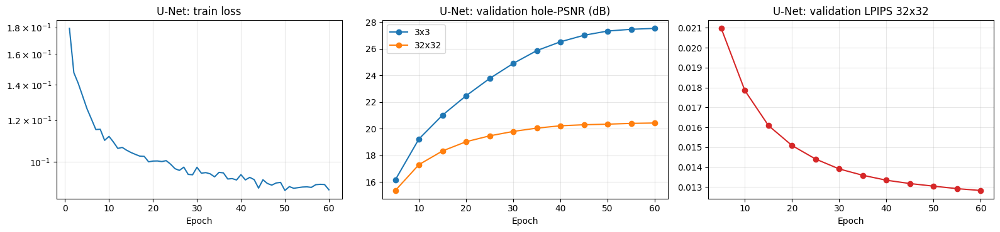

In [19]:
if unet_history is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    axes[0].plot(unet_history["epoch"], unet_history["train_loss"]); axes[0].set_title("U-Net: train loss"); axes[0].set_yscale("log")
    h = unet_history.dropna(subset=["val_psnr_hole_3"])
    axes[1].plot(h["epoch"], h["val_psnr_hole_3"], "o-", label="3x3")
    axes[1].plot(h["epoch"], h[f"val_psnr_hole_{BIG}"], "o-", label=f"{BIG}x{BIG}")
    axes[1].set_title("U-Net: validation hole-PSNR (dB)"); axes[1].legend()
    axes[2].plot(h["epoch"], h["val_lpips_big"], "o-", color="C3"); axes[2].set_title(f"U-Net: validation LPIPS {BIG}x{BIG}")
    for ax in axes: ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
    plt.tight_layout(); fig.savefig(OUTPUT_DIR / "unet_training_curves.png", dpi=120); plt.show()


### GAN

GAN 1/40 x0.33:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 2/40 x0.67:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 3/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 4/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 5/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

[GAN] epoch 5: hole L1=0.0948 tv=0.0417 adv=0.508 fm=0.006 D=1.434 (real +0.27 / fake -0.51) | val hole-PSNR 3x3=27.51 dB, 32x32=20.37 dB, LPIPS 32x32=0.0128  <- best val LPIPS


... (19 outputs left out)

GAN 22/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 23/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 24/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 25/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

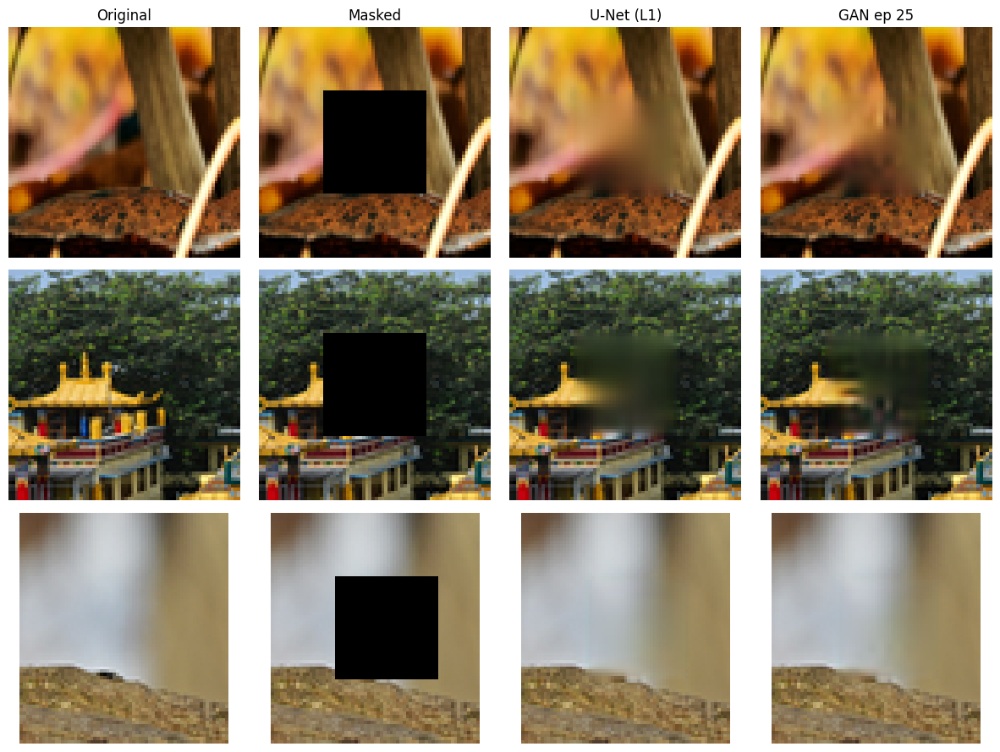

[GAN] epoch 25: hole L1=0.0912 tv=0.0586 adv=0.529 fm=0.008 D=1.390 (real +0.35 / fake -0.52) | val hole-PSNR 3x3=27.56 dB, 32x32=20.26 dB, LPIPS 32x32=0.0093  <- best val LPIPS


GAN 26/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 27/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 28/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 29/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 30/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

... (8 outputs left out)

GAN 37/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 38/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 39/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

GAN 40/40 x1.00:   0%|          | 0/90 [00:00<?, ?it/s]

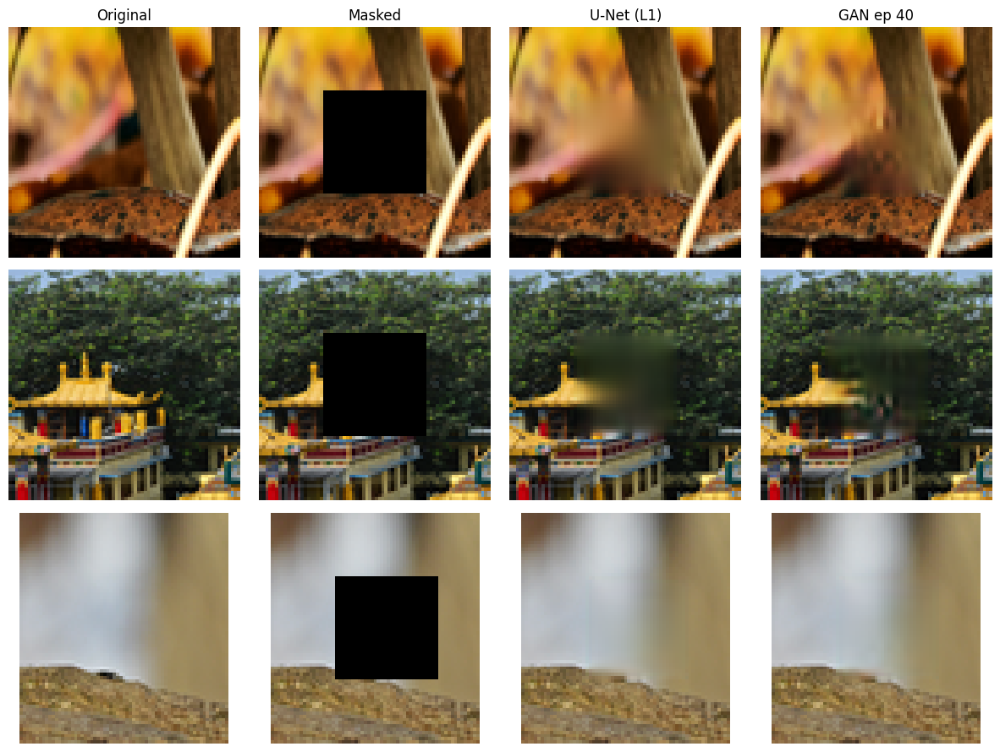

[GAN] epoch 40: hole L1=0.0901 tv=0.0599 adv=0.638 fm=0.009 D=1.272 (real +0.45 / fake -0.61) | val hole-PSNR 3x3=27.78 dB, 32x32=20.24 dB, LPIPS 32x32=0.0088
GAN model = gan_last_ema.pth
{'val_psnr_hole_3': 27.7788, 'val_psnr_hole_32': 20.235, 'val_lpips_big': 0.0088}


In [20]:
def train_gan(G, D, baseline, epochs=EPOCHS_GAN, lr_g=LR_GAN_G, lr_d=LR_GAN_D, adv_w=ADV_W, fm_w=FM_W,
              tv_w=TV_W, ramp_epochs=GAN_RAMP, ema_decay=EMA_GAN, win=D_WINDOW):
    G.to(DEVICE); D.to(DEVICE)
    ema = copy.deepcopy(G).eval()
    for p in ema.parameters(): p.requires_grad_(False)
    optG = torch.optim.AdamW(G.parameters(), lr=lr_g, betas=(0.5, 0.999), weight_decay=1e-4)
    optD = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    total = epochs * len(inpaint_loader)
    lr_lambda = lambda s: min(1.0, (s + 1) / 300) * max(0.5 * (1 + math.cos(math.pi * s / total)), 0.005)
    schedG = torch.optim.lr_scheduler.LambdaLR(optG, lr_lambda)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)          # G only; D runs in fp32
    rows, best_lpips = [], float("inf")

    for epoch in range(1, epochs + 1):
        scale = min(1.0, epoch / ramp_epochs)
        G.train(); D.train()
        s = dict(hole=0.0, tv=0.0, adv=0.0, fm=0.0, d=0.0, dr=0.0, df=0.0); n = 0; n_gan = 0
        pbar = tqdm(inpaint_loader, desc=f"GAN {epoch}/{epochs} x{scale:.2f}")
        for clean in pbar:
            clean = clean.to(DEVICE, non_blocking=True)
            corrupted, mask = apply_inpainting_mask(clean, [random.choice(HOLE_SIZES) for _ in range(clean.shape[0])])
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                raw = G(corrupted, mask)[0]
            raw = raw.float()
            comp = raw * mask + corrupted * (1 - mask)

            loss_g, hole = inpaint_loss_tv(raw, comp, clean, mask, w_tv=tv_w)
            s["hole"] += hole.item() * clean.size(0); n += clean.size(0)
            s["tv"] += tv_loss(comp.detach(), mask).item() * clean.size(0)

            idx = (mask.sum((1, 2, 3)) > 100).nonzero().squeeze(1)
            if idx.numel() > 0:
                (cr, cf), cm = crop_around_hole([clean[idx], comp[idx].detach()], mask[idx], win)
                (real_a, fake_a), m_a = diff_aug([cr, cf], cm)
                d_real, _ = D(real_a, m_a); d_fake, _ = D(fake_a, m_a)
                loss_d = F.relu(1 - d_real).mean() + F.relu(1 + d_fake).mean()
                optD.zero_grad(set_to_none=True); loss_d.backward(); optD.step()

                for p in D.parameters(): p.requires_grad_(False)
                (cr, cf), cm = crop_around_hole([clean[idx], comp[idx]], mask[idx], win)
                (real_a, fake_a), m_a = diff_aug([cr, cf], cm)
                g_fake, f_fake = D(fake_a, m_a)
                with torch.no_grad():
                    _, f_real = D(real_a, m_a)
                adv = -g_fake.mean()
                fm = sum(F.l1_loss(a, b) for a, b in zip(f_fake, f_real)) / len(f_fake)
                loss_g = loss_g + scale * (adv_w * adv + fm_w * fm)
                for p in D.parameters(): p.requires_grad_(True)

                k = idx.numel(); n_gan += k
                s["adv"] += adv.item() * k; s["fm"] += fm.item() * k; s["d"] += loss_d.item() * k
                s["dr"] += d_real.mean().item() * k; s["df"] += d_fake.mean().item() * k

            optG.zero_grad(set_to_none=True)
            scaler.scale(loss_g).backward()
            scaler.unscale_(optG)
            nn.utils.clip_grad_norm_(G.parameters(), 1.0)
            scaler.step(optG); scaler.update(); schedG.step()

            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), G.parameters()):
                    pe.mul_(ema_decay).add_(pm.detach(), alpha=1 - ema_decay)
                for be, bm in zip(ema.buffers(), G.buffers()):
                    be.copy_(bm)
            pbar.set_postfix(hole=f"{hole.item():.4f}")

        row = {"epoch": epoch, **{k: v / max(n_gan if k in ("adv", "fm", "d", "dr", "df") else n, 1) for k, v in s.items()}}
        if epoch % VAL_EVERY == 0 or epoch == epochs:
            v = validate(ema); row.update(v)
            mark = ""
            if v["val_lpips_big"] < best_lpips:
                best_lpips = v["val_lpips_big"]
                torch.save(ema.state_dict(), GAN_BEST_CKPT)
                mark = "  <- best val LPIPS"
            torch.save(ema.state_dict(), GAN_LAST_CKPT)
            log_val_samples(ema, epoch, "GAN", baseline=baseline, out_dir=OUTPUT_DIR / "val_samples" / "gan",
                            show=(epoch % 25 == 0 or epoch == epochs))
            print(f"[GAN] epoch {epoch}: hole L1={row['hole']:.4f} tv={row['tv']:.4f} adv={row['adv']:.3f} fm={row['fm']:.3f} "
                  f"D={row['d']:.3f} (real {row['dr']:+.2f} / fake {row['df']:+.2f}) | val hole-PSNR 3x3={v['val_psnr_hole_3']:.2f} dB, "
                  f"{BIG}x{BIG}={v[f'val_psnr_hole_{BIG}']:.2f} dB, LPIPS {BIG}x{BIG}={v['val_lpips_big']:.4f}{mark}")
        rows.append(row)
    final = GAN_BEST_CKPT if GAN_SELECT == "lpips" else GAN_LAST_CKPT
    ema.load_state_dict(torch.load(final, map_location=DEVICE, weights_only=True))
    print(f"GAN model = {final.name}")
    return ema.eval(), pd.DataFrame(rows)

GAN_LAST_CKPT = OUTPUT_DIR / "gan_last_ema.pth"
GAN_BEST_CKPT = OUTPUT_DIR / "gan_best_val_lpips_ema.pth"
final_ckpt = GAN_BEST_CKPT if GAN_SELECT == "lpips" else GAN_LAST_CKPT
if LOAD_IF_EXISTS and final_ckpt.exists():
    gan = GatedUNet(UNET_BASE).to(DEVICE)
    gan.load_state_dict(torch.load(final_ckpt, map_location=DEVICE, weights_only=True)); gan.eval()
    gan_history = load_history(OUTPUT_DIR / "gan_history.csv")
    print("Loaded GAN-trained generator from", final_ckpt)
else:
    G = GatedUNet(UNET_BASE); G.load_state_dict(unet.state_dict())
    D = SNPatchD(D_BASE)
    gan, gan_history = train_gan(G, D, baseline=unet)
    save_history(gan_history, OUTPUT_DIR / "gan_history.csv")

print({k: round(x, 4) for k, x in validate(gan).items()})


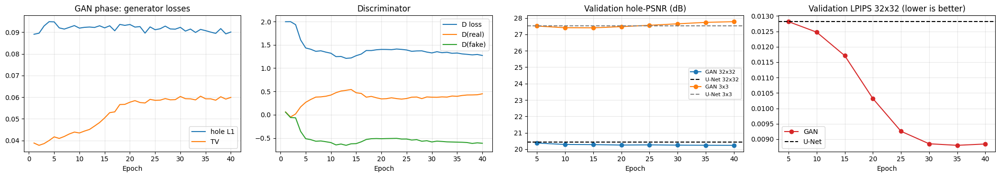

In [21]:
if gan_history is not None:
    fig, axes = plt.subplots(1, 4, figsize=(21, 3.8))
    axes[0].plot(gan_history["epoch"], gan_history["hole"], label="hole L1"); axes[0].plot(gan_history["epoch"], gan_history["tv"], label="TV")
    axes[0].set_title("GAN phase: generator losses"); axes[0].legend()
    axes[1].plot(gan_history["epoch"], gan_history["d"], label="D loss"); axes[1].plot(gan_history["epoch"], gan_history["dr"], label="D(real)")
    axes[1].plot(gan_history["epoch"], gan_history["df"], label="D(fake)"); axes[1].set_title("Discriminator"); axes[1].legend()
    h = gan_history.dropna(subset=["val_psnr_hole_3"])
    u = validate(unet)
    axes[2].plot(h["epoch"], h[f"val_psnr_hole_{BIG}"], "o-", label=f"GAN {BIG}x{BIG}")
    axes[2].axhline(u[f"val_psnr_hole_{BIG}"], color="k", ls="--", label=f"U-Net {BIG}x{BIG}")
    axes[2].plot(h["epoch"], h["val_psnr_hole_3"], "o-", label="GAN 3x3")
    axes[2].axhline(u["val_psnr_hole_3"], color="gray", ls="--", label="U-Net 3x3")
    axes[2].set_title("Validation hole-PSNR (dB)"); axes[2].legend(fontsize=8)
    axes[3].plot(h["epoch"], h["val_lpips_big"], "o-", color="C3", label="GAN")
    axes[3].axhline(u["val_lpips_big"], color="k", ls="--", label="U-Net")
    axes[3].set_title(f"Validation LPIPS {BIG}x{BIG} (lower is better)"); axes[3].legend()
    for ax in axes: ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
    plt.tight_layout(); fig.savefig(OUTPUT_DIR / "gan_training_curves.png", dpi=120); plt.show()


In [22]:
TELEA_RADII = list(range(1, 21))

def telea_baseline(corrupted_hwc, mask_hw, radius=3):
    img_u8 = np.clip(corrupted_hwc * 255, 0, 255).astype(np.uint8)
    mask_u8 = (mask_hw > 0.5).astype(np.uint8) * 255
    return cv2.inpaint(img_u8, mask_u8, radius, cv2.INPAINT_TELEA).astype(np.float32) / 255.0

@torch.no_grad()
def find_best_telea_radius(paths, radii=TELEA_RADII):
    rows = []
    for size in HOLE_SIZES:
        for path in tqdm(paths, desc=f"TELEA radius search {size}x{size} (validation)"):
            clean_np = load_rgb(path)
            mask_np, _, _ = fixed_mask(path, size)
            corrupted_np = clean_np * (1 - mask_np[..., None])
            clean, mask = to_tensor(clean_np), torch.from_numpy(mask_np)[None, None].to(DEVICE)
            for r in radii:
                res = to_tensor(telea_baseline(corrupted_np, mask_np, r))
                rows.append({"size": size, "radius": r, "PSNR_hole": hole_psnr(res, clean, mask)})
    df = pd.DataFrame(rows)
    summary = df.groupby(["size", "radius"])["PSNR_hole"].mean().reset_index()
    best = summary.loc[summary.groupby("size")["PSNR_hole"].idxmax()].reset_index(drop=True)
    return summary, best, {int(s): int(r) for s, r in zip(best["size"], best["radius"])}

telea_summary, best_telea, BEST_TELEA_RADII = find_best_telea_radius(val_paths)
print("Best TELEA radii (chosen on validation):", BEST_TELEA_RADII)
display(best_telea)


TELEA radius search 3x3 (validation):   0%|          | 0/80 [00:00<?, ?it/s]

TELEA radius search 32x32 (validation):   0%|          | 0/80 [00:00<?, ?it/s]

Best TELEA radii (chosen on validation): {3: 1, 32: 15}


,size,radius,PSNR_hole
0,3,1,28.026688
1,32,15,18.957588


In [23]:
inpaint_models = {"Gated U-Net (L1)": unet, "Gated U-Net + GAN": gan}
METHOD_ORDER = ["Masked input", "OpenCV TELEA", "Gated U-Net (L1)", "Gated U-Net + GAN"]
EVAL_SETS = {"validation": val_paths, "test": test_paths}
INP_COLS = ["PSNR_hole", *METRIC_COLS]

@torch.no_grad()
def evaluate_inpainting(models, paths, tta=TTA_FINAL, set_name=""):
    for m in models.values(): m.eval()
    rows = []
    for size in HOLE_SIZES:
        for path in tqdm(paths, desc=f"Inpainting eval [{set_name}] {size}x{size}"):
            clean_np = load_rgb(path)
            mask_np, _, _ = fixed_mask(path, size)
            corrupted_np = clean_np * (1 - mask_np[..., None])
            clean, corrupted = to_tensor(clean_np), to_tensor(corrupted_np)
            mask = torch.from_numpy(mask_np)[None, None].to(DEVICE)
            cands = [("Masked input", corrupted),
                     ("OpenCV TELEA", to_tensor(telea_baseline(corrupted_np, mask_np, BEST_TELEA_RADII[size])))]
            cands += [(n, predict(m, corrupted, mask, tta)) for n, m in models.items()]
            for method, result in cands:
                rows.append({"task": "inpainting", "set": set_name, "setting": f"mask={size}x{size}", "image": path.name,
                             "method": method, "PSNR_hole": hole_psnr(result, clean, mask), **compute_metrics(result, clean)})
    return pd.DataFrame(rows)

inpaint_results, inpaint_summary = {}, {}
for set_name, paths in EVAL_SETS.items():
    inpaint_results[set_name] = evaluate_inpainting(inpaint_models, paths, set_name=set_name)
    inpaint_summary[set_name] = (inpaint_results[set_name].groupby(["setting", "method"], sort=False)[INP_COLS]
                                 .mean().reset_index())
    inpaint_results[set_name].to_csv(OUTPUT_DIR / f"inpainting_per_image_{set_name}.csv", index=False)
    inpaint_summary[set_name].rename(columns=METRIC_ARROWS).to_csv(OUTPUT_DIR / f"inpainting_summary_{set_name}.csv", index=False)
    print(f"\n=== Inpainting, {set_name} set ({len(paths)} images) ===")
    display(inpaint_summary[set_name].rename(columns=METRIC_ARROWS))


Inpainting eval [validation] 3x3:   0%|          | 0/80 [00:00<?, ?it/s]

Inpainting eval [validation] 32x32:   0%|          | 0/80 [00:00<?, ?it/s]


=== Inpainting, validation set (80 images) ===


,setting,method,PSNR hole ↑,PSNR ↑,SSIM ↑,SNE ↓,LPIPS (Alex) ↓,LPIPS (VGG) ↓
0,mask=3x3,Masked input,8.413205,47.035579,0.999346,7.207696,0.005105,0.004034
1,mask=3x3,OpenCV TELEA,28.026688,66.649061,0.999961,0.241146,0.000038,0.000053
2,mask=3x3,Gated U-Net (L1),28.138195,66.760568,0.999966,0.164427,0.000025,0.000046
3,mask=3x3,Gated U-Net + GAN,28.396536,67.018909,0.999968,0.158524,0.000023,0.000043
4,mask=32x32,Masked input,7.785267,25.847067,0.979979,746.900552,0.036623,0.027749
5,mask=32x32,OpenCV TELEA,18.957588,37.019387,0.989964,64.146012,0.014654,0.013926
6,mask=32x32,Gated U-Net (L1),20.623891,38.685690,0.991588,49.168711,0.012858,0.011896
7,mask=32x32,Gated U-Net + GAN,20.664008,38.725807,0.991728,50.992589,0.009064,0.010166


Inpainting eval [test] 3x3:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


Inpainting eval [test] 32x32:   0%|          | 0/100 [00:00<?, ?it/s]


=== Inpainting, test set (100 images) ===


,setting,method,PSNR hole ↑,PSNR ↑,SSIM ↑,SNE ↓,LPIPS (Alex) ↓,LPIPS (VGG) ↓
0,mask=3x3,Masked input,8.624765,47.247139,0.999343,6.857594,0.005301,0.003697
1,mask=3x3,OpenCV TELEA,29.575807,67.811956,0.999964,0.220134,0.000027,0.000052
2,mask=3x3,Gated U-Net (L1),29.623320,68.245693,0.999969,0.179316,0.000018,0.000089
3,mask=3x3,Gated U-Net + GAN,29.973439,68.595812,0.999971,0.169072,0.000016,0.000053
4,mask=32x32,Masked input,8.915971,26.797152,0.980382,728.923029,0.035027,0.026935
5,mask=32x32,OpenCV TELEA,20.845613,38.726794,0.990034,65.481237,0.013287,0.013976
6,mask=32x32,Gated U-Net (L1),21.608002,39.669801,0.991593,53.346182,0.011806,0.012112
7,mask=32x32,Gated U-Net + GAN,21.635521,39.697320,0.991714,55.457398,0.008107,0.010131


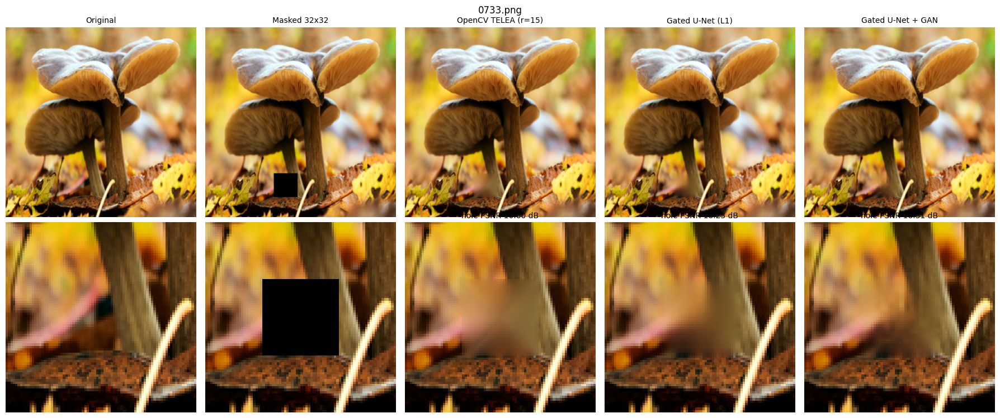

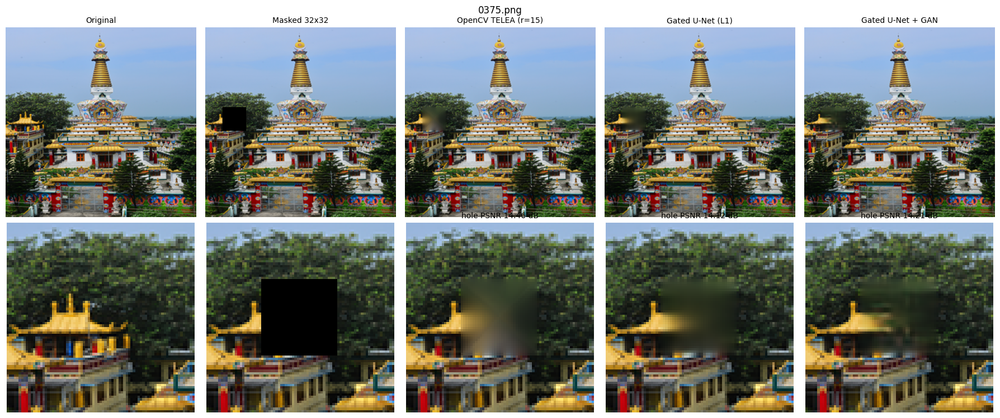

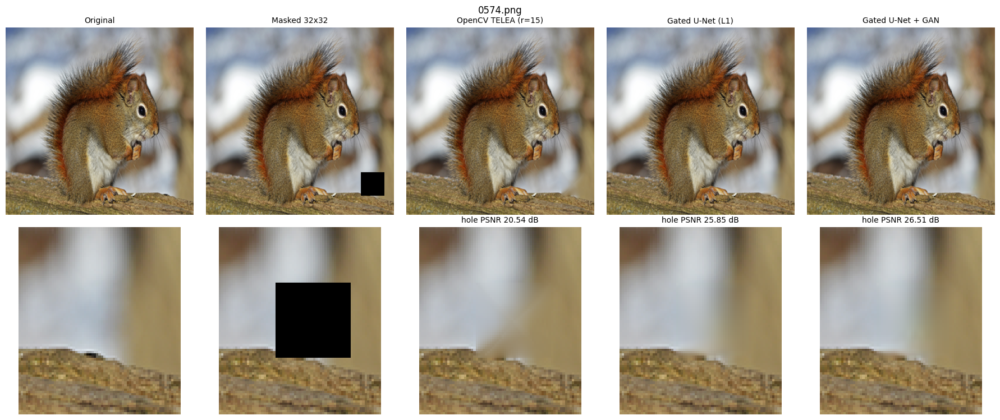

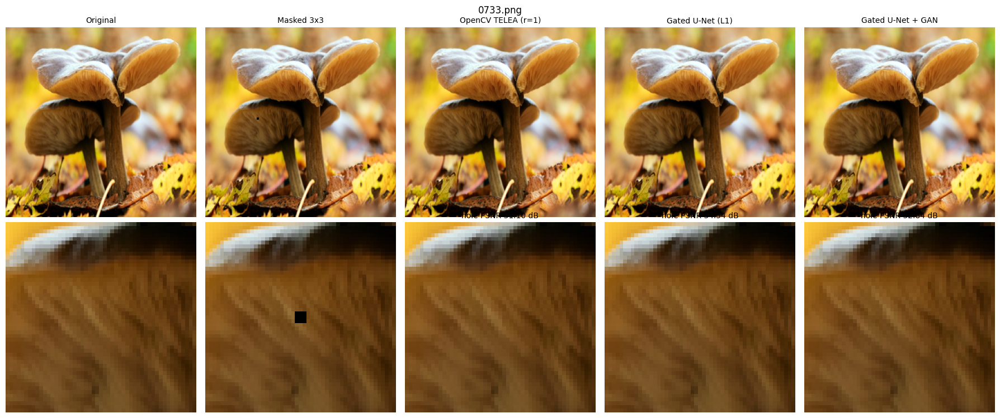

In [25]:
@torch.no_grad()
def render_comparison(path, hole_size, models, tta=TTA_FINAL, zoom_ctx=24, save_path=None, show=False):
    clean_np = load_rgb(path)
    mask, y, x = fixed_mask(path, hole_size)
    corrupted_np = clean_np * (1 - mask[..., None])
    corrupted, mask_t, clean_t = to_tensor(corrupted_np), torch.from_numpy(mask)[None, None].to(DEVICE), to_tensor(clean_np)

    images = [clean_np, corrupted_np, telea_baseline(corrupted_np, mask, BEST_TELEA_RADII[hole_size])]
    titles = ["Original", f"Masked {hole_size}x{hole_size}", f"OpenCV TELEA (r={BEST_TELEA_RADII[hole_size]})"]
    for name, model in models.items():
        model.eval()
        images.append(predict(model, corrupted, mask_t, tta)[0].permute(1, 2, 0).cpu().numpy()); titles.append(name)

    y0, y1 = max(0, y - zoom_ctx), min(IMAGE_SIZE, y + hole_size + zoom_ctx)
    x0, x1 = max(0, x - zoom_ctx), min(IMAGE_SIZE, x + hole_size + zoom_ctx)
    fig, axes = plt.subplots(2, len(images), figsize=(3.6 * len(images), 7.6))
    for i, (im, t) in enumerate(zip(images, titles)):
        axes[0, i].imshow(im); axes[0, i].set_title(t, fontsize=10); axes[0, i].axis("off")
        axes[1, i].imshow(im[y0:y1, x0:x1], interpolation="nearest"); axes[1, i].axis("off")
        if i > 1:
            axes[1, i].set_title(f"hole PSNR {hole_psnr(to_tensor(im), clean_t, mask_t):.2f} dB", fontsize=10)
    fig.suptitle(path.name, fontsize=12)
    plt.tight_layout()
    if save_path is not None:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=100, bbox_inches="tight")
    if show: plt.show()
    plt.close(fig)

for p in val_paths[:3]:
    render_comparison(p, BIG, inpaint_models, show=True)
render_comparison(val_paths[0], 3, inpaint_models, show=True)


In [26]:
COMP_DIR = OUTPUT_DIR / "comparisons_inpainting"

for set_name, paths in EVAL_SETS.items():
    for size in HOLE_SIZES:
        out = COMP_DIR / set_name / f"mask_{size}x{size}"
        for p in tqdm(paths, desc=f"Saving comparisons [{set_name}] {size}x{size}"):
            render_comparison(p, size, inpaint_models, save_path=out / f"{p.stem}.png")
    shutil.make_archive(str(OUTPUT_DIR / f"comparisons_inpainting_{set_name}"), "zip", COMP_DIR / set_name)

for set_name in EVAL_SETS:
    n = len(list((COMP_DIR / set_name).rglob("*.png")))
    print(f"{set_name}: {n} comparison images in {(COMP_DIR / set_name).resolve()}  (+ zip: comparisons_inpainting_{set_name}.zip)")


Saving comparisons [validation] 3x3:   0%|          | 0/80 [00:00<?, ?it/s]

Saving comparisons [validation] 32x32:   0%|          | 0/80 [00:00<?, ?it/s]

Saving comparisons [test] 3x3:   0%|          | 0/100 [00:00<?, ?it/s]

Saving comparisons [test] 32x32:   0%|          | 0/100 [00:00<?, ?it/s]

validation: 160 comparison images in /content/results_div2k/comparisons_inpainting/validation  (+ zip: comparisons_inpainting_validation.zip)
test: 200 comparison images in /content/results_div2k/comparisons_inpainting/test  (+ zip: comparisons_inpainting_test.zip)


## 5. Summary tables and export

In [52]:
inp_all = pd.concat([inpaint_summary[s].assign(set=s) for s in EVAL_SETS], ignore_index=True)
all_summary = pd.concat([denoise_summary.assign(task="Denoising", set="test"),
                         inp_all.assign(task="Inpainting")], ignore_index=True, sort=False)
all_summary.rename(columns=METRIC_ARROWS).to_csv(OUTPUT_DIR / "all_results_summary.csv", index=False)

print(f"Denoising results, {len(test_paths)} images")
display(denoise_summary.rename(columns=METRIC_ARROWS))

s = list(EVAL_SETS.keys())[1]
paths = EVAL_SETS[s]

print(f"Inpainting results, {len(paths)} images")
display(inpaint_summary[s].rename(columns=METRIC_ARROWS))


Denoising results, 100 images


,setting,method,PSNR ↑,SSIM ↑,SNE ↓,LPIPS (Alex) ↓,LPIPS (VGG) ↓
0,sigma=0.01,Noisy input,40.076378,0.972854,19.331253,0.008314,0.050127
1,sigma=0.01,Bilateral,37.307911,0.977970,38.909135,0.007530,0.042922
2,sigma=0.01,CNN 32x6,40.370813,0.983790,19.071969,0.007835,0.044685
3,sigma=0.01,CNN 64x8,40.611053,0.986195,18.150780,0.007543,0.042502
4,sigma=0.03,Noisy input,30.609065,0.841264,171.097100,0.065428,0.149589
5,sigma=0.03,Bilateral,30.843195,0.908679,171.217742,0.044380,0.145968
6,sigma=0.03,CNN 32x6,33.167407,0.905607,95.376526,0.059581,0.135760
7,sigma=0.03,CNN 64x8,33.910188,0.924516,81.037840,0.056762,0.130066


Inpainting results, 100 images


,setting,method,PSNR hole ↑,PSNR ↑,SSIM ↑,SNE ↓,LPIPS (Alex) ↓,LPIPS (VGG) ↓
0,mask=3x3,Masked input,8.624765,47.247139,0.999343,6.857594,0.005301,0.003697
1,mask=3x3,OpenCV TELEA,29.575807,67.811956,0.999964,0.220134,0.000027,0.000052
2,mask=3x3,Gated U-Net (L1),29.623320,68.245693,0.999969,0.179316,0.000018,0.000089
3,mask=3x3,Gated U-Net + GAN,29.973439,68.595812,0.999971,0.169072,0.000016,0.000053
4,mask=32x32,Masked input,8.915971,26.797152,0.980382,728.923029,0.035027,0.026935
5,mask=32x32,OpenCV TELEA,20.845613,38.726794,0.990034,65.481237,0.013287,0.013976
6,mask=32x32,Gated U-Net (L1),21.608002,39.669801,0.991593,53.346182,0.011806,0.012112
7,mask=32x32,Gated U-Net + GAN,21.635521,39.697320,0.991714,55.457398,0.008107,0.010131
